In [5]:
!pip -q install pandas pyarrow matplotlib seaborn


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("SWYNEX CyberClean is ready!")
print("Libraries imported successfully.")

SWYNEX CyberClean is ready!
Libraries imported successfully.


In [7]:
from google.colab import files

uploaded = files.upload()

Saving Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet to Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv.parquet


In [8]:
import pandas as pd

file_name = next(iter(uploaded))
df = pd.read_parquet(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (286467, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [9]:
# SWYNEX CyberClean: Initial Data Quality Audit

print("DATA QUALITY REPORT")
print("-" * 40)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print("Infinite values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(10)
      .to_frame("Missing Values")
)

DATA QUALITY REPORT
----------------------------------------
Rows: 286467
Columns: 79
Duplicate rows: 72353
Missing values: 15
Infinite values: 727


,Missing Values
Flow Bytes/s,15
Flow Duration,0
Destination Port,0
Total Backward Packets,0
Total Length of Fwd Packets,0
Total Length of Bwd Packets,0
Total Fwd Packets,0
Fwd Packet Length Max,0
Fwd Packet Length Min,0
Fwd Packet Length Std,0


In [10]:
# SWYNEX CyberClean: Data Cleaning

df_clean = df.copy()

# Replace infinite values with missing values
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove exact duplicate rows
df_clean.drop_duplicates(inplace=True)

# Fill missing numeric values with their column median
numeric_cols = df_clean.select_dtypes(include=np.number).columns
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(
    df_clean[numeric_cols].median()
)

print("CLEANING SUMMARY")
print("-" * 35)
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining duplicates:", df_clean.duplicated().sum())
print("Remaining infinite values:",
      np.isinf(df_clean.select_dtypes(include=np.number)).sum().sum())

CLEANING SUMMARY
-----------------------------------
Original shape: (286467, 79)
Cleaned shape: (214114, 79)
Remaining missing values: 0
Remaining duplicates: 0
Remaining infinite values: 0


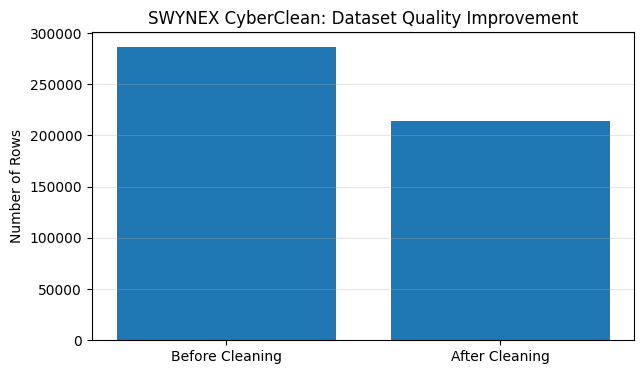

Duplicate rows removed: 72,353
Rows retained: 74.7%


In [11]:
# SWYNEX CyberClean: Before vs After

before = df.shape[0]
after = df_clean.shape[0]
removed = before - after

plt.figure(figsize=(7, 4))
plt.bar(["Before Cleaning", "After Cleaning"], [before, after])
plt.title("SWYNEX CyberClean: Dataset Quality Improvement")
plt.ylabel("Number of Rows")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(f"Duplicate rows removed: {removed:,}")
print(f"Rows retained: {after / before:.1%}")

In [12]:
# Save the cleaned dataset
output_file = "SWYNEX_CyberClean.csv"

df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File:", output_file)

Cleaned dataset saved successfully!
File: SWYNEX_CyberClean.csv


In [13]:
from google.colab import files
files.download("SWYNEX_CyberClean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Data Preparation Assumptions

- **Dataset:** CIC-IDS2017 network traffic dataset, accessed through a public dataset mirror.
- **Duplicate records:** Exact duplicate rows were removed to reduce repeated observations.
- **Infinite values:** Positive and negative infinity values were converted to missing values.
- **Missing values:** Missing numeric values were filled using their column median.
- **Data preservation:** The original dataset was retained in `df`; cleaning was performed on a separate copy.
- **Validation:** The cleaned dataset was checked for remaining missing values, duplicates, and infinite values.
- **Scope:** This project focuses on data preparation and quality checks, not on training an intrusion detection model.